# 4. Does it differ across the city? (RQ4)

Multiscale GWR lets each variable work at its own spatial scale. A bandwidth near the full sample means
a relationship is the same citywide; a small one means it changes from one neighborhood to the next.
Script: `scripts/06_mgwr.py` (the fit takes a few minutes, so saved results are shown).

_Part of the Chicago Energy Burden project (James Rocco Quantitative Data Research Scholarship, Lake Forest College). Run the pipeline scripts first, or read the executed copy on GitHub._

In [1]:
import json, warnings
import numpy as np, pandas as pd, geopandas as gpd
from IPython.display import Image, Markdown, display
from ceb import config
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
T, F = config.TABLES, config.FIGURES
gdf = gpd.read_file(config.PROCESSED / "chicago_tracts.gpkg")
sample = gdf[gdf["in_main_sample"].astype(bool)].reset_index(drop=True)
print(f"{len(gdf)} tracts mostly inside Chicago; {len(sample)} in the analysis sample")

782 tracts mostly inside Chicago; 768 in the analysis sample


In [2]:
s = json.loads((T / "mgwr_summary.json").read_text())
display(pd.Series(s["bandwidths"], name="bandwidth (nearest tracts)").to_frame())
display(pd.Series(s["share_tracts_significant"], name="share of tracts significant").round(3).to_frame())
{k: s[k] for k in ["adj_r2", "aicc", "max_local_condition_number", "moran_resid_I"]}

,bandwidth (nearest tracts)
CONSTANT,433.0
ln_income,18.0
pct_black,205.0
pct_hispanic,98.0
pct_pre1950,210.0
pct_renter,760.0
pct_multifam5,157.0


,share of tracts significant
CONSTANT,1.000
ln_income,0.492
pct_black,1.000
pct_hispanic,0.491
pct_pre1950,0.444
pct_renter,0.000
pct_multifam5,0.951


{'adj_r2': 0.9299897113461166,
 'aicc': 338.846677965372,
 'max_local_condition_number': 9.282588149367191,
 'moran_resid_I': -0.027272889272055345}

## Model comparison (energy burden, original units)

In [3]:
pd.read_csv(T / "model_comparison_burden.csv").round(3)

,model,aic,logll,moran_resid_I,pseudo_r2,effective_parameters,delta_aic
0,OLS,1855.024,-920.512,0.363,NaN,NaN,542.248
1,Spatial error,1631.771,-808.886,-0.036,NaN,NaN,318.994
2,Spatial lag,1657.559,-820.780,0.072,NaN,NaN,344.783
3,Spatial Durbin,1611.812,-791.906,-0.030,NaN,NaN,299.035
4,MGWR,1312.777,-509.638,-0.027,0.943,145.75,0.000


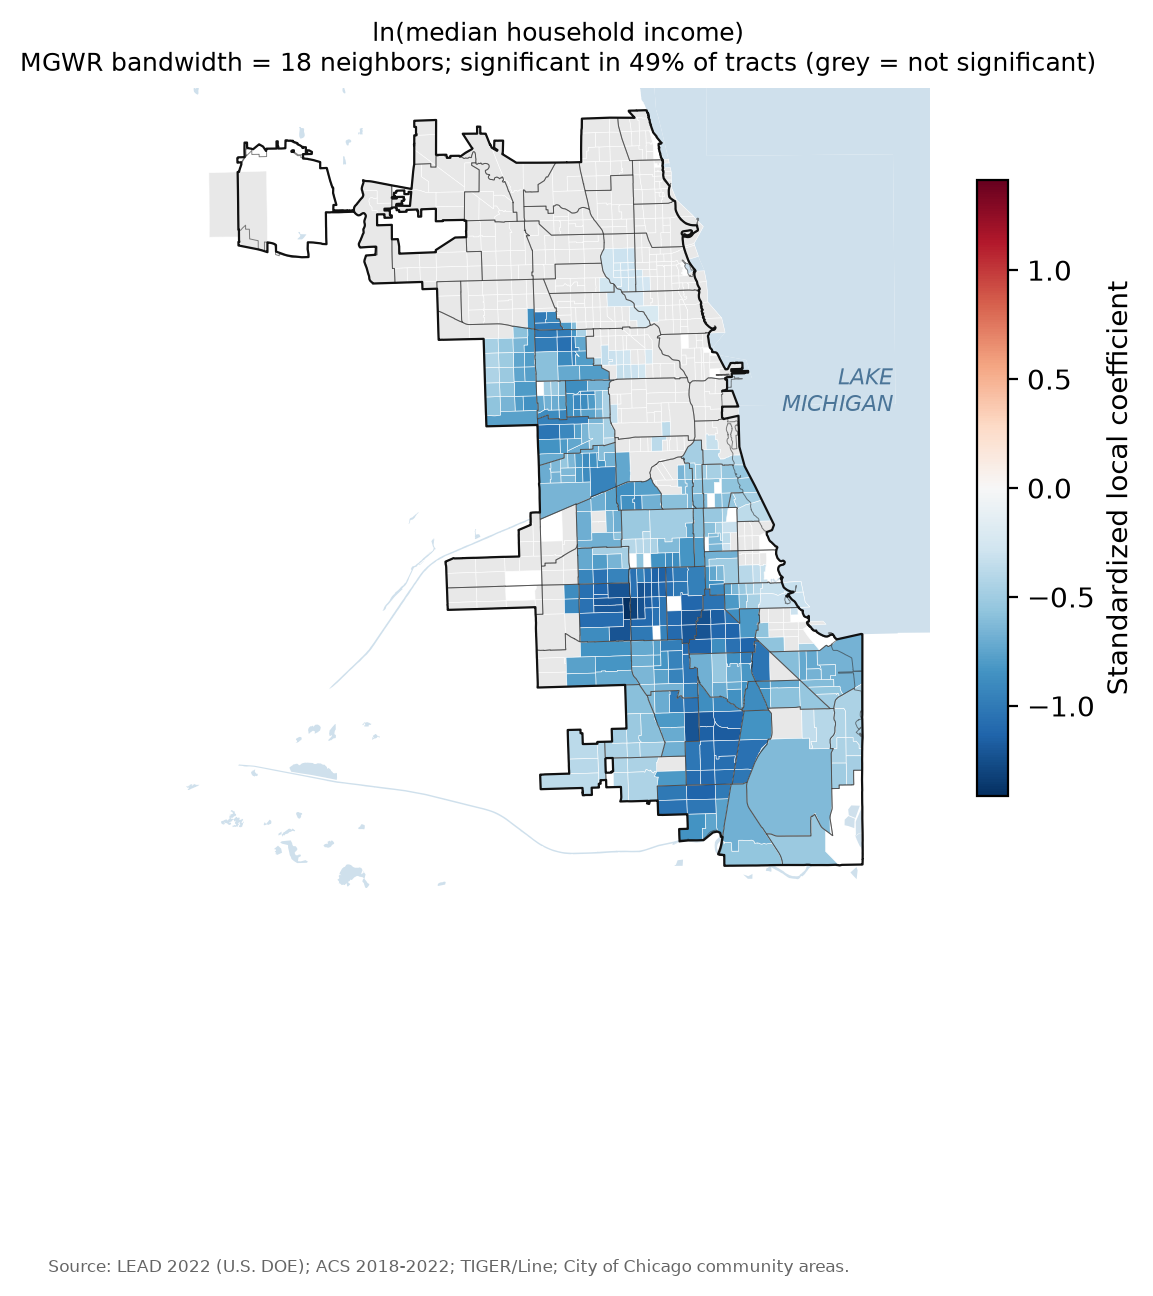

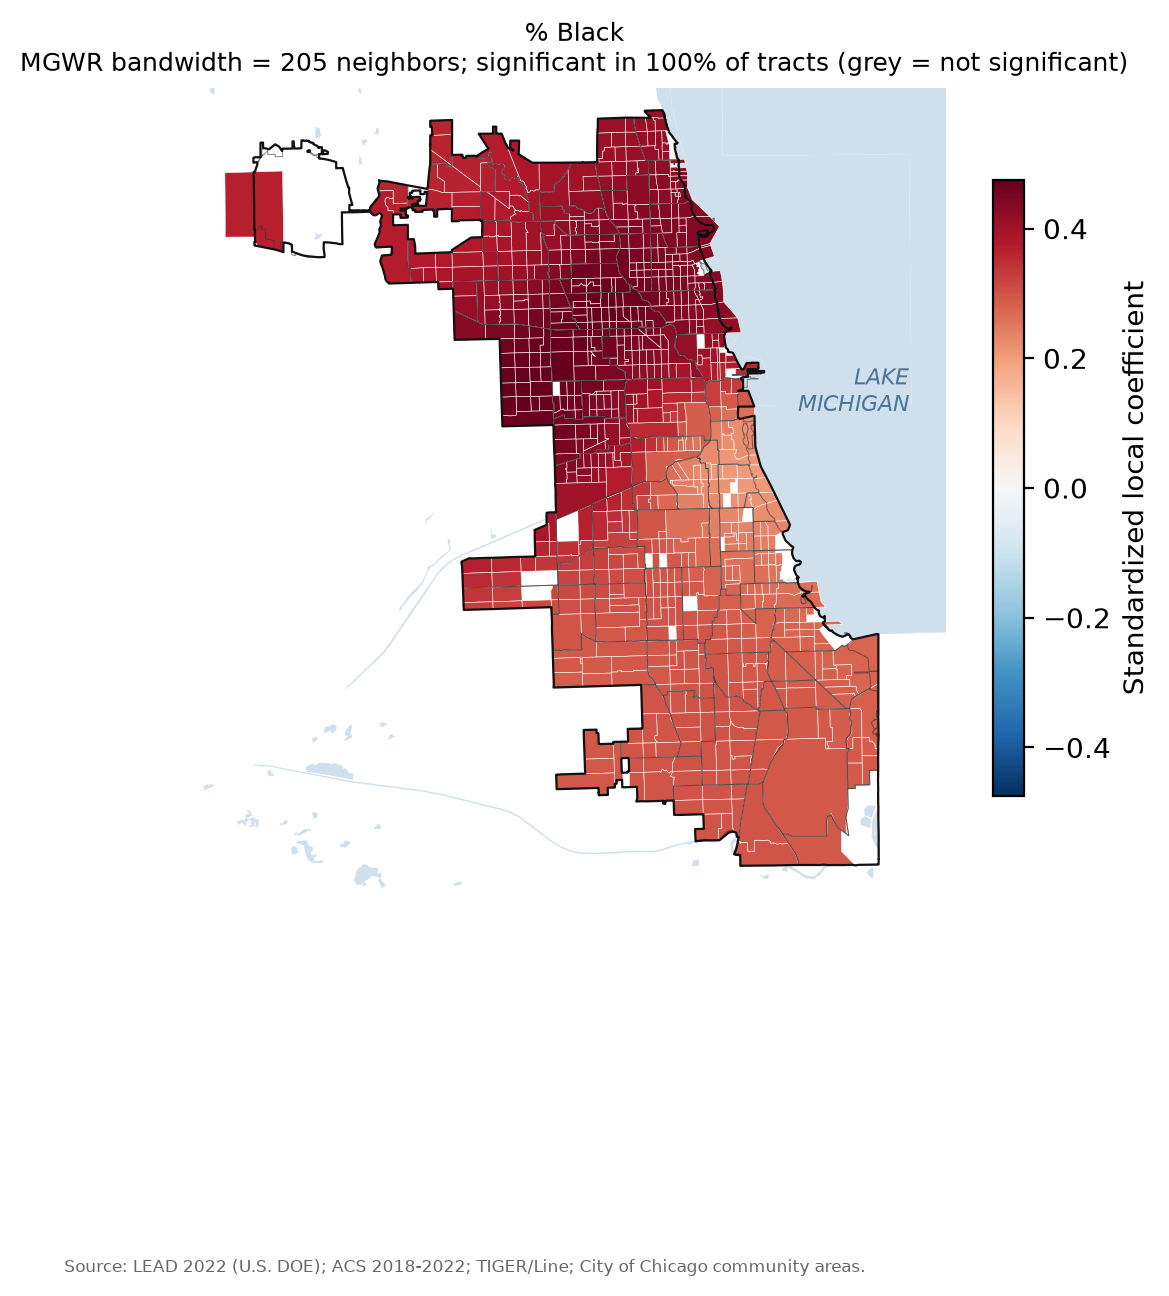

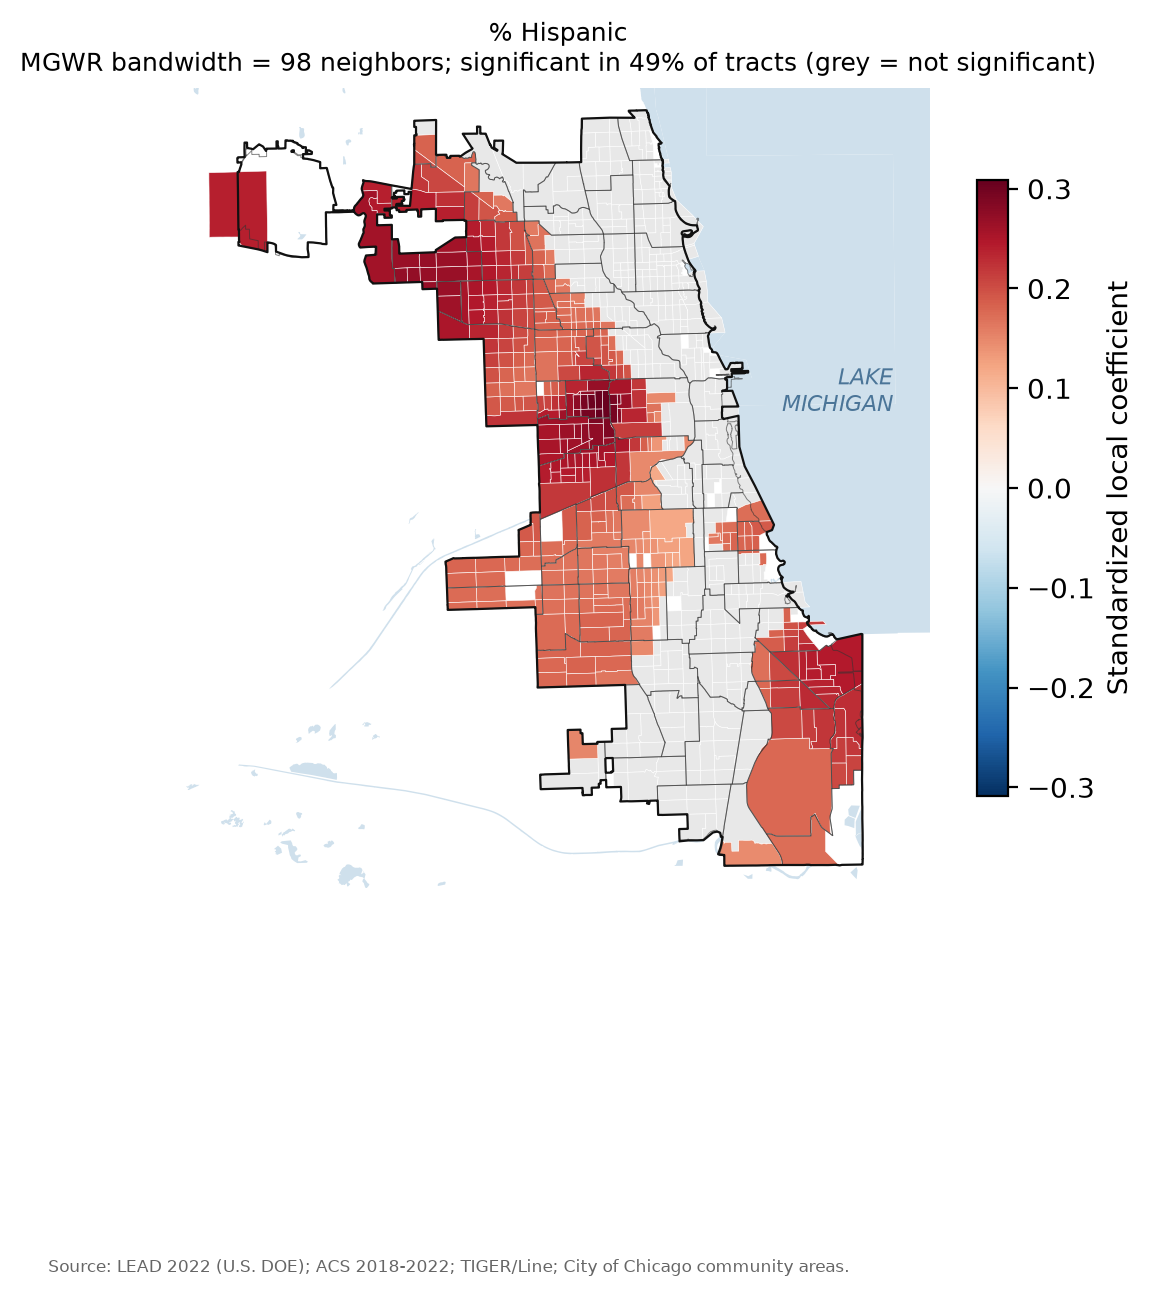

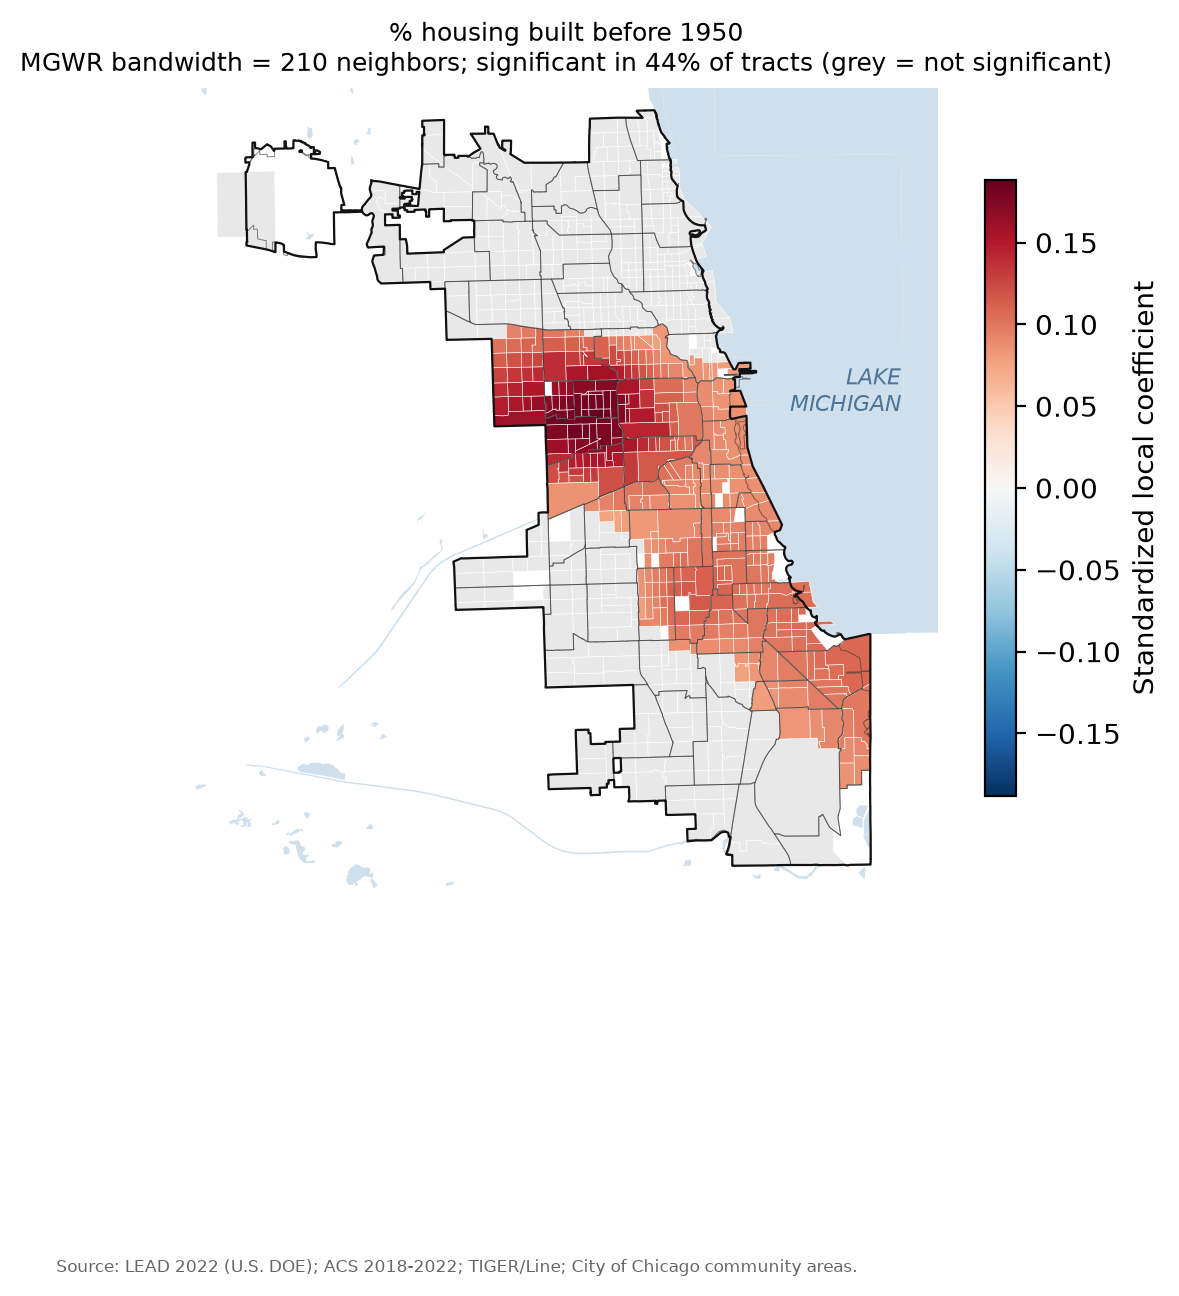

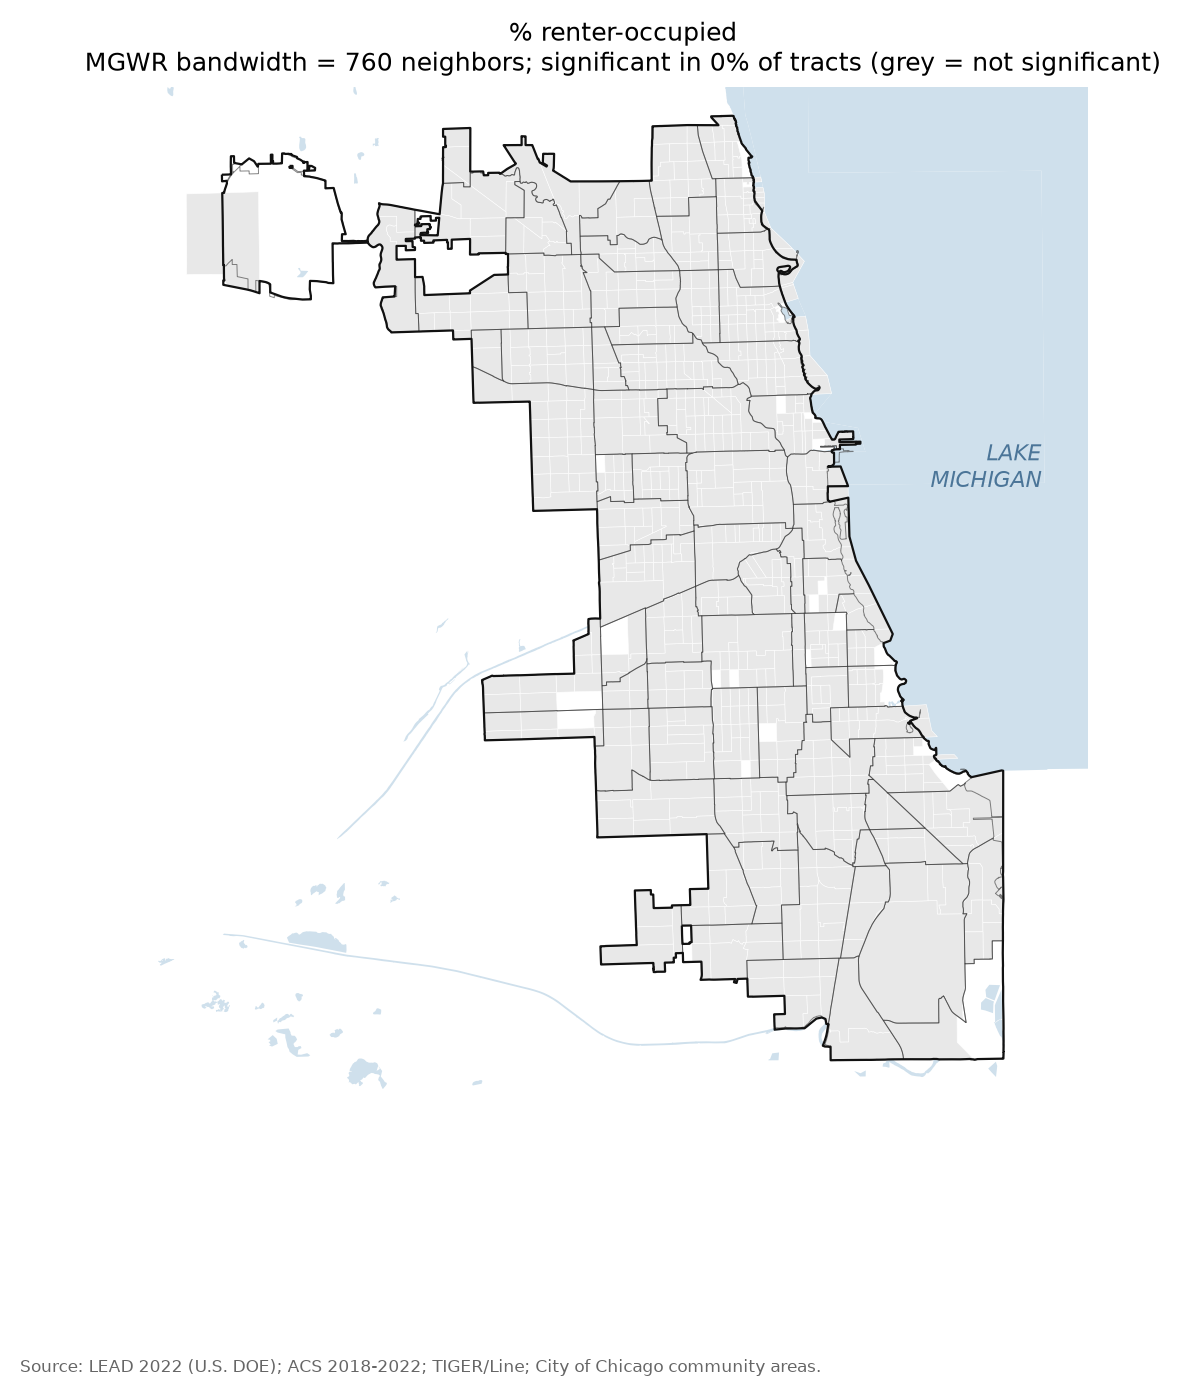

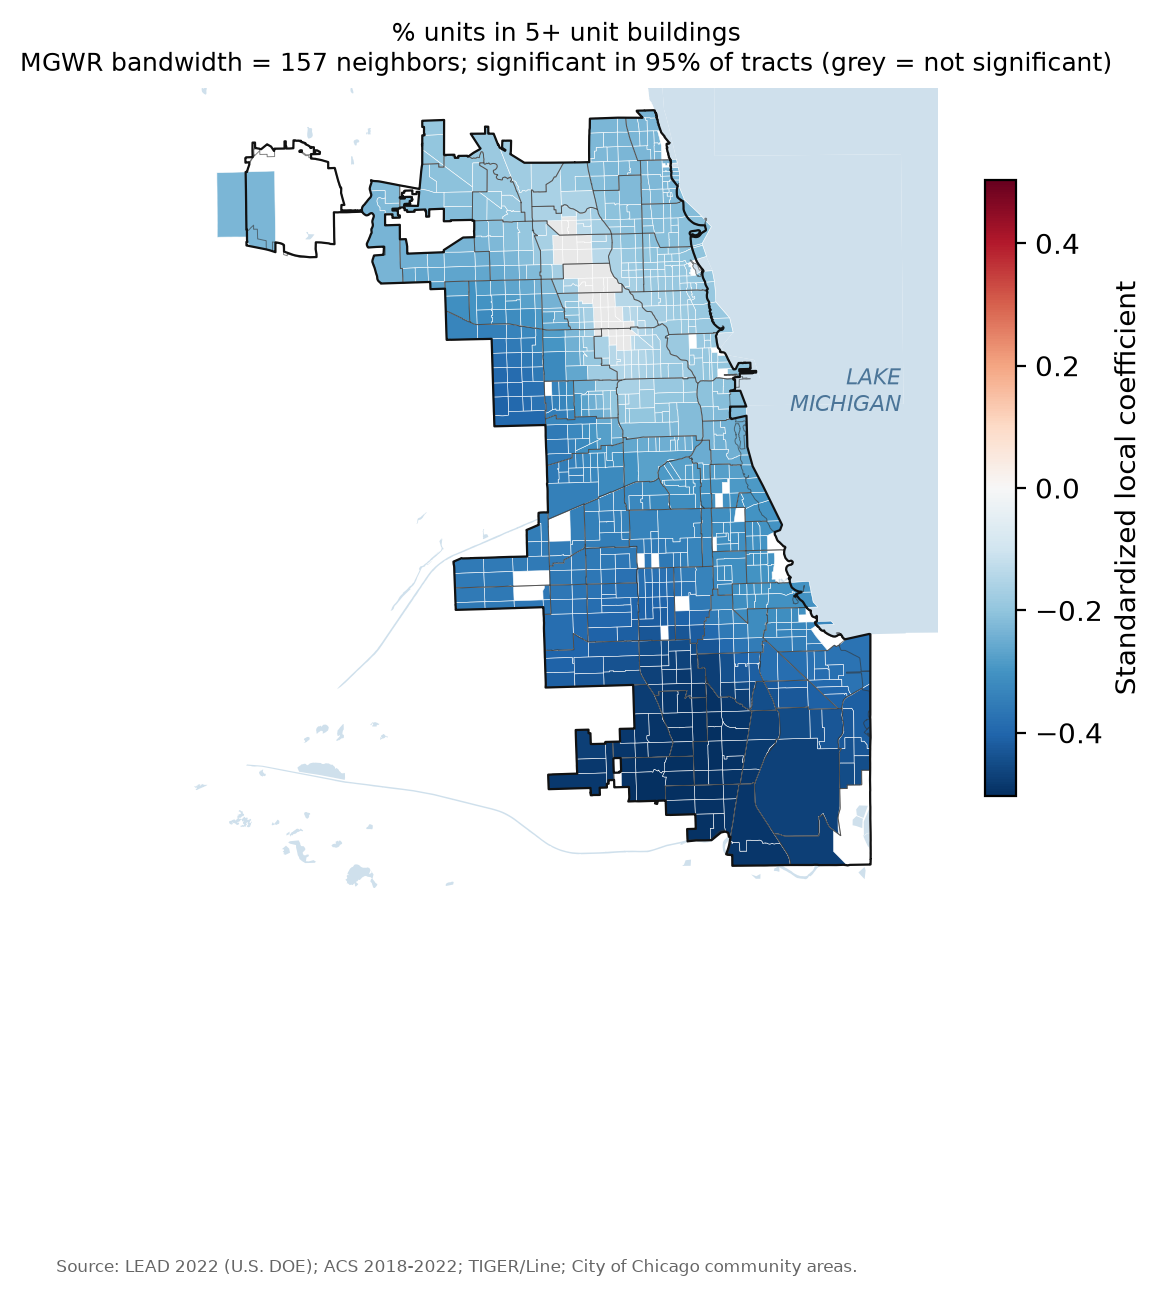

In [4]:
for v in ["ln_income", "pct_black", "pct_hispanic", "pct_pre1950", "pct_renter", "pct_multifam5"]:
    display(Image(F / f"mgwr_{v}.png", width=430))